In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt

# --------------------------------- Internal imports --------------------------------- #
from radiopyo_vec.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo_vec.sim_env import SimEnv
from radiopyo_vec.ode_solver import derive, jac, reconstruct_Ri_from_res
import radiopyo_vec as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

In [3]:
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

In [8]:
file = Path(rf"{rp.__path__[0]}\data\reactions_water.ron")
beam = PulsedBeam("e",10000, 500e-6, 250e-6, max_dose=100)
beam = ConstantBeam("e", 1e7, max_dose=10)
env = SimEnv.from_ron_file(file)

In [9]:
beam

ConstantBeam(particle='e', dose_rate=10000000.0, timer=Timer(period=inf, on_time=inf), max_dose=10, time_at_max_dose=1e-06, dose_per_pulse=inf, peak_dose_rate=10000000.0)

In [10]:
kwargs = {}
kwargs["max_step"] = np.inf
kwargs["first_step"] = 1e-10
kwargs["atol"] = 1e-7
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 10]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, t_span[1], step=1e-3))
y0 = env.initial_values()
ab_mat = env.make_acidBase_matrix()
ki_mat = env.make_kreaction_matrix()
Gi_mat = env.make_radiolytic_vector()
Enzi   = env.make_enzymatic_matrix()

for sp in env.species:
    print(f"{sp.index}) {sp.label} = {y0[sp.index]:.2g}")

0) H2O = 5.5e+07
1) H_plus = 0.1
2) OH_minus = 0.1
3) OH_r = 0
4) O_r_minus = 0
5) H2O2 = 0
6) HO2_minus = 0
7) HO2_r = 0
8) O2_r_minus = 0
9) e_aq = 0
10) H_r = 0
11) H2 = 0
12) O2 = 50
13) O2_minus_minus = 0
14) O3_minus = 0


 ## Debug Jacobian

In [55]:
y = np.array(np.arange(2,17))
for sp in env.species:
    print(f"{sp.index:02d}) {sp.label} {' '*(15-len(sp.label))} = {y[sp.index]:.2g}")

00) H2O              = 2
01) H_plus           = 3
02) OH_minus         = 4
03) OH_r             = 5
04) O_r_minus        = 6
05) H2O2             = 7
06) HO2_minus        = 8
07) HO2_r            = 9
08) O2_r_minus       = 10
09) e_aq             = 11
10) H_r              = 12
11) H2               = 13
12) O2               = 14
13) O2_minus_minus   = 15
14) O3_minus         = 16


In [69]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
res = np.prod(res, axis=1).T * ki_mat[0] 
matprint(np.matmul(ki_mat[1], res.T))

0  0  0             0             0            0          0         0           0           0             0         0           0  0  0  
0  0  0             0             0            0          0         0           0           0             0         0           0  0  0  
0  0  0             0             0            0          0         0           0           0             0         0           0  0  0  
0  0  0  -6.64714e+11       3.6e+06   1.2208e+11      1e+09         0      -4e+10    -4.5e+10    -3.437e+10  -2.1e+08           0  0  0  
0  0  0      1.68e+08  -2.98404e+11            0          0         0    -3.6e+09   -1.32e+11             0         0   -2.16e+10  0  0  
0  0  0       5.5e+10             0  -1.2208e+11          0   1.2e+11           0    -7.7e+10     8.937e+10         0           0  0  0  
0  0  0        -6e+10             0            0   -7.6e+10         0           0    -2.8e+10             0         0           0  0  0  
0  0  0         6e+10             

In [45]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    matprint(res[:,:,sp.index])
    print()

e_aq
 2  1  
22  1  
12  1  
 5  1  
 6  1  
 3  1  
 7  1  
 8  1  
14  1  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  



In [44]:
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    for _ in range(ki_mat[3].shape[2]):
        matprint(ki_mat[3][:,:,_,sp.index])
        print()

e_aq
1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0

## Run Sim

In [15]:
sol = solve_ivp(derive, t_span, y0, args=(ab_mat, ki_mat, Gi_mat, beam),t_eval=tspan, jac=jac, **kwargs)
sim_t, res = sol.t, sol.y

## Plot

In [ ]:
env.species_labels()

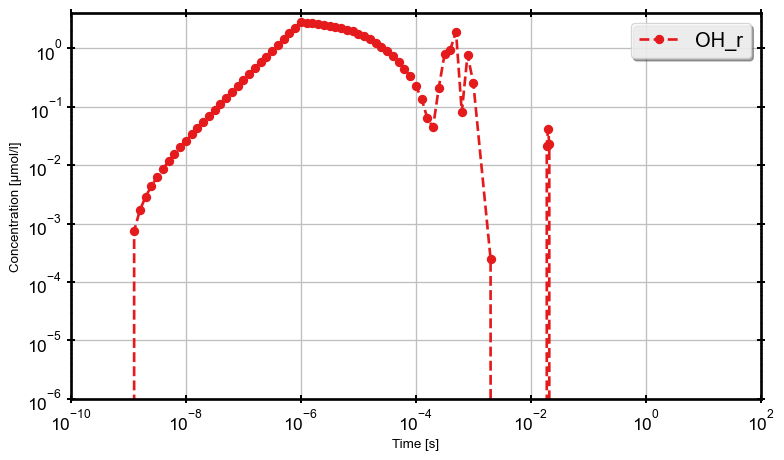

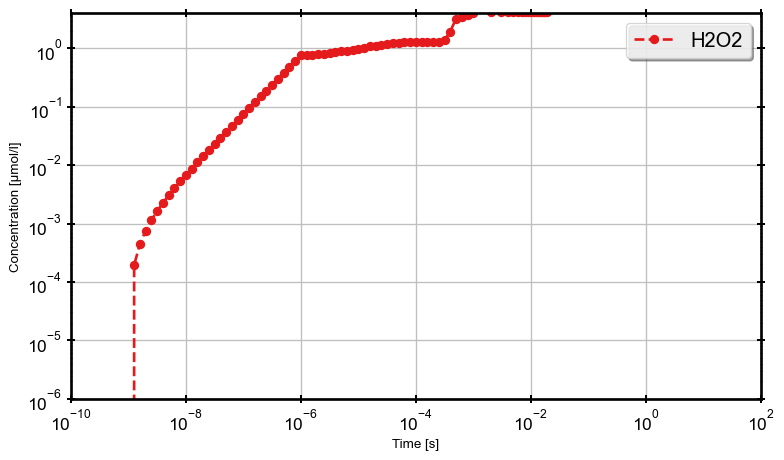

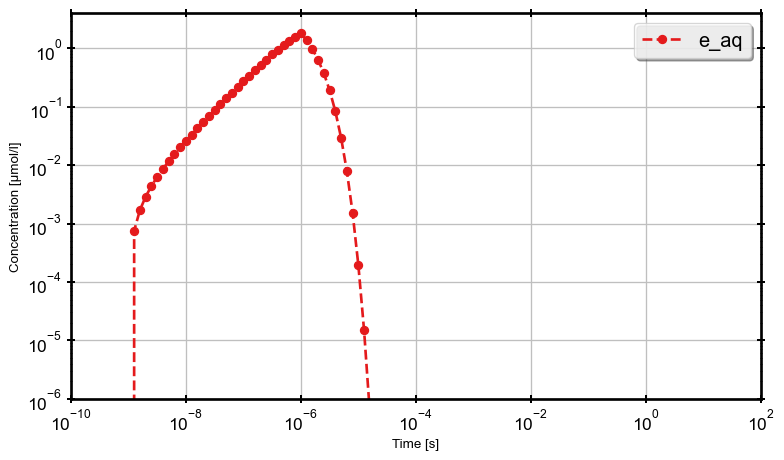

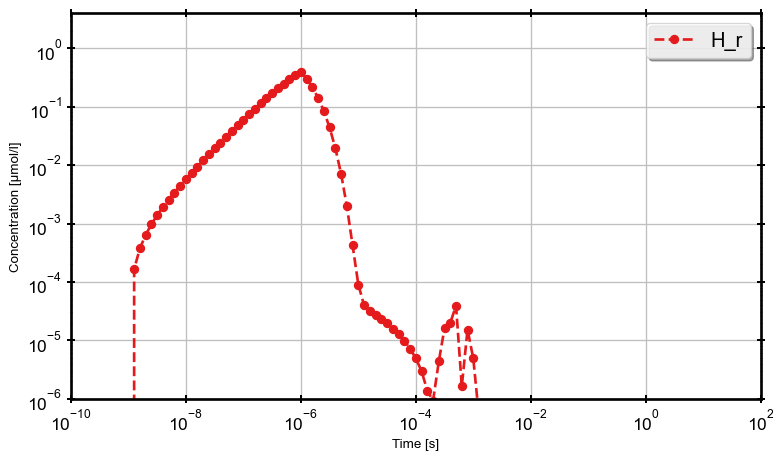

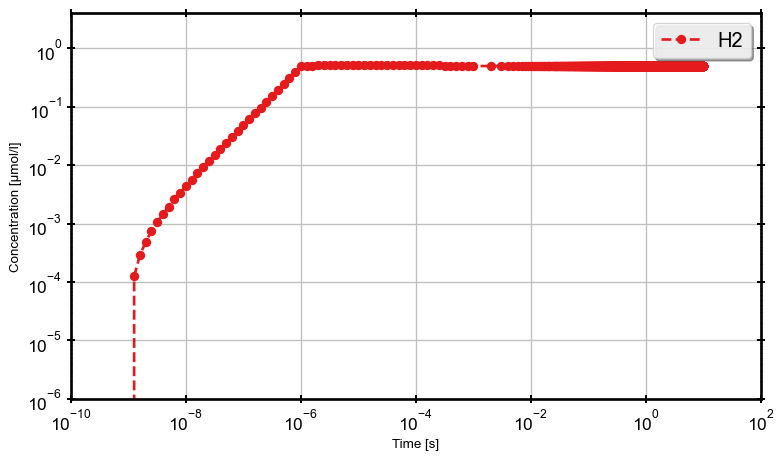

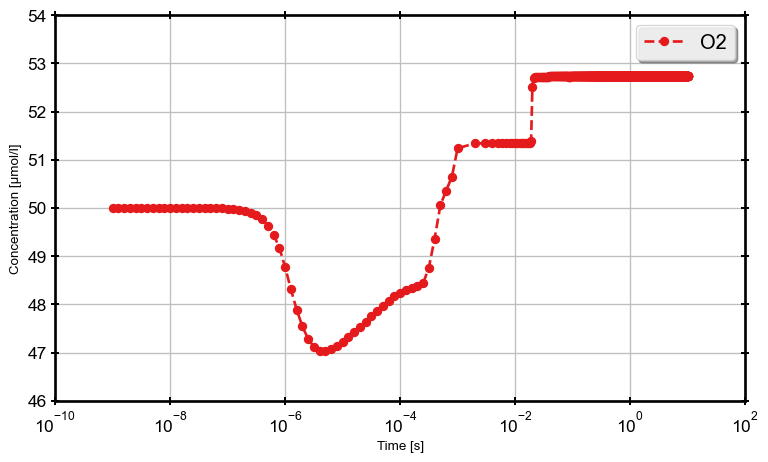

In [12]:
for (label, sp) in zip(env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        #sp = sp * 1e6
        if label=="O2":
            ax.semilogx(time , sp , label=label)
            #ax.set_ylim([49.9, 50.01])
        else:
            ax.loglog(time , sp , label=label)
            ax.set_ylim(bottom=1e-6, top=4)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Explore reaction Rates:

In [16]:
df = reconstruct_Ri_from_res(sim_t, res, env, ab_mat, ki_mat, Gi_mat, beam, Enzi) 

<Axes: >

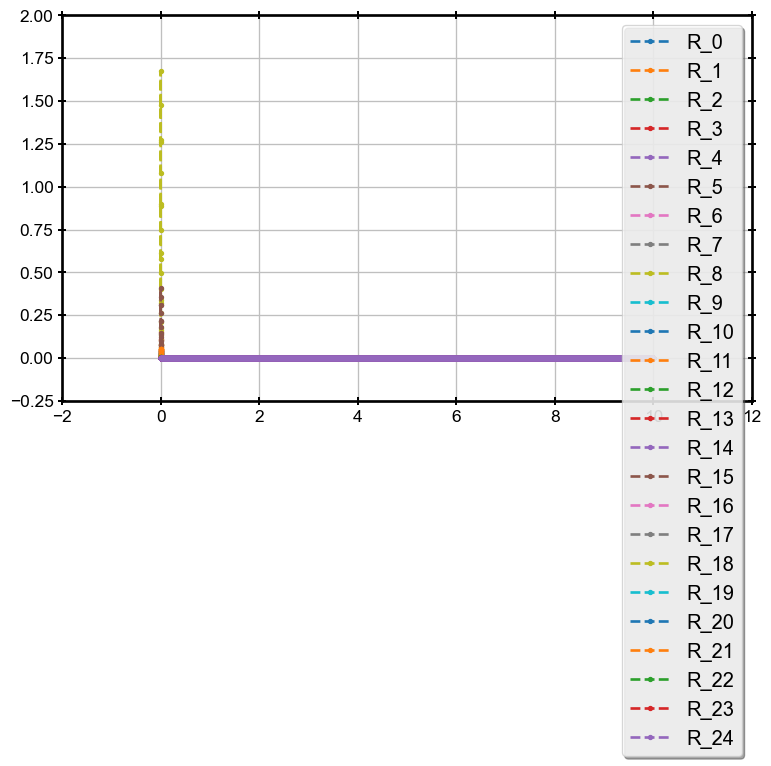

In [18]:
df.plot()